In [ ]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEMENTE = 42
np.random.seed(SEMENTE)


CAMINHO_CSV = Path("../dataset/cenario/cenarioB_nominais_ordinais.csv")
PASTA_SAIDA = Path("resultados_arvore_cenarioB")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

PROPORCAO_TESTE = 0.30
CLASSES = ["Dropout", "Enrolled", "Graduate"]

MODO_RAPIDO = True
N_FOLDS = 5 if MODO_RAPIDO else 10
N_REPETICOES = 1 if MODO_RAPIDO else 3
PROFUNDIDADES = list(range(1, 11 if MODO_RAPIDO else 21))

IMPLEMENTACAO_CV = "propria"
MIN_SAMPLES_LEAF = 5
N_COMPONENTES_PCA = 0.95

CRITERIOS = ["gini", "entropia"]
MODOS = ["nenhum", "pca"]

print(f"Modo: {'rápido' if MODO_RAPIDO else 'completo'} | "
      f"CV: {N_FOLDS} folds × {N_REPETICOES} repetições | "
      f"Profundidades: {PROFUNDIDADES[0]} a {PROFUNDIDADES[-1]}")

Modo: rápido | CV: 5 folds × 1 repetições | Profundidades: 1 a 10


In [ ]:
caminho = CAMINHO_CSV.expanduser()
if not caminho.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {caminho.resolve()}\n"
        "Verifique CAMINHO_CSV na célula de configurações."
    )

data = pd.read_csv(caminho, sep=";", decimal=",")
if "Target" not in data.columns:
    raise ValueError("A coluna Target não foi encontrada. Confira o separador do CSV.")

mapa_classes = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
y = data["Target"].map(mapa_classes)
if y.isna().any():
    valores = data.loc[y.isna(), "Target"].unique()
    raise ValueError(f"Valores inesperados em Target: {valores}")
y = y.astype(int)

X = data.drop(columns="Target")
try:
    X = X.astype(float)
except (ValueError, TypeError) as erro:
    raise ValueError(
        "Há colunas não numéricas no dataset. Use o CSV com "
        "atributos categóricos já codificados numericamente."
    ) from erro
if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Há valores ausentes ou infinitos em X; trate-os antes dos experimentos.")

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=PROPORCAO_TESTE, random_state=SEMENTE, stratify=y
)
print(f"Dados: {len(X)} linhas e {X.shape[1]} atributos")
print(f"Treino: {len(X_treino)} | Teste reservado: {len(X_teste)}")

Dados: 4208 linhas e 85 atributos
Treino: 2945 | Teste reservado: 1263


In [ ]:
def entropia_contagens(cont):
    cont = np.asarray(cont, dtype=float)
    total = cont.sum(axis=-1, keepdims=True)
    p = cont / np.where(total == 0, 1, total)
    log_p = np.log2(p, out=np.zeros_like(p), where=p > 0)
    return -(p * log_p).sum(axis=-1)


def gini_contagens(cont):
    cont = np.asarray(cont, dtype=float)
    total = cont.sum(axis=-1, keepdims=True)
    p = cont / np.where(total == 0, 1, total)
    return 1.0 - (p ** 2).sum(axis=-1)


def entropia(y):
    return float(entropia_contagens(np.bincount(y)))


def gini(y):
    return float(gini_contagens(np.bincount(y)))


def ganho_informacao(y_pai, y_esq, y_dir, impureza=entropia):
    n = len(y_pai)
    return (impureza(y_pai)
            - len(y_esq) / n * impureza(y_esq)
            - len(y_dir) / n * impureza(y_dir))

In [ ]:
class No:
    def __init__(self, atributo=None, limiar=None, esquerda=None, direita=None, classe=None):
        self.atributo = atributo
        self.limiar = limiar
        self.esquerda = esquerda
        self.direita = direita
        self.classe = classe


class ArvoreDecisao:
    def __init__(self, criterio="gini", max_depth=5, min_samples_leaf=5):
        self.criterio = criterio
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.impureza = gini_contagens if criterio == "gini" else entropia_contagens

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.n_classes = int(y.max()) + 1
        self.raiz = self._construir(X, y, profundidade=0)
        return self

    def _construir(self, X, y, profundidade):
        contagem = np.bincount(y, minlength=self.n_classes)
        classe_majoritaria = int(np.argmax(contagem))

        if (profundidade >= self.max_depth
                or len(y) < 2 * self.min_samples_leaf
                or contagem.max() == len(y)):
            return No(classe=classe_majoritaria)

        j, limiar = self._melhor_divisao(X, y)
        if j is None:
            return No(classe=classe_majoritaria)

        esq = X[:, j] <= limiar
        return No(atributo=j, limiar=limiar,
                  esquerda=self._construir(X[esq], y[esq], profundidade + 1),
                  direita=self._construir(X[~esq], y[~esq], profundidade + 1))

    def _melhor_divisao(self, X, y):
        n, d = X.shape
        Y1 = np.eye(self.n_classes)[y]
        total = Y1.sum(axis=0)
        imp_pai = self.impureza(total)

        melhor_ganho, melhor_j, melhor_limiar = 0.0, None, None
        n_esq = np.arange(1, n)
        n_dir = n - n_esq

        for j in range(d):
            ordem = np.argsort(X[:, j])
            x_ord = X[ordem, j]

            cont_esq = np.cumsum(Y1[ordem], axis=0)[:-1]
            cont_dir = total - cont_esq

            valido = ((x_ord[:-1] != x_ord[1:])
                      & (n_esq >= self.min_samples_leaf)
                      & (n_dir >= self.min_samples_leaf))
            if not valido.any():
                continue

            imp_esq = self.impureza(cont_esq[valido])
            imp_dir = self.impureza(cont_dir[valido])
            ganho = imp_pai - (n_esq[valido] * imp_esq + n_dir[valido] * imp_dir) / n

            k = int(np.argmax(ganho))
            if ganho[k] > melhor_ganho:
                i = np.flatnonzero(valido)[k]
                melhor_ganho = ganho[k]
                melhor_j = j
                melhor_limiar = (x_ord[i] + x_ord[i + 1]) / 2

        return melhor_j, melhor_limiar

    def _prever_um(self, x):
        no = self.raiz
        while no.classe is None:
            no = no.esquerda if x[no.atributo] <= no.limiar else no.direita
        return no.classe

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._prever_um(x) for x in X])

In [6]:
def matriz_confusao(y_real, y_pred, n_classes=3):
    M = np.zeros((n_classes, n_classes), dtype=int)
    for real, predito in zip(y_real, y_pred):
        M[int(real), int(predito)] += 1
    return M

def relatorio_metricas(M):
    total = M.sum()
    if total == 0:
        raise ValueError("Não é possível avaliar uma matriz de confusão vazia.")

    precisao, revocacao, f1 = [], [], []
    vp_lista, fp_lista, fn_lista = [], [], []
    for classe in range(M.shape[0]):
        vp = M[classe, classe]
        fp = M[:, classe].sum() - vp
        fn = M[classe, :].sum() - vp
        p = vp / (vp + fp) if vp + fp else 0.0
        r = vp / (vp + fn) if vp + fn else 0.0
        f = 2 * p * r / (p + r) if p + r else 0.0
        vp_lista.append(vp)
        fp_lista.append(fp)
        fn_lista.append(fn)
        precisao.append(p)
        revocacao.append(r)
        f1.append(f)

    return {
        "VP_por_classe": np.asarray(vp_lista),
        "FP_por_classe": np.asarray(fp_lista),
        "FN_por_classe": np.asarray(fn_lista),
        "precisao": np.asarray(precisao),
        "revocacao": np.asarray(revocacao),
        "f1": np.asarray(f1),
        "acuracia": np.trace(M) / total,
        "f1_macro": float(np.mean(f1)),
        "acuracia_balanceada": float(np.mean(revocacao)),
    }

def tabela_por_classe(m):
    return pd.DataFrame({
        "Classe": CLASSES,
        "VP": m["VP_por_classe"],
        "FP": m["FP_por_classe"],
        "FN": m["FN_por_classe"],
        "Precisão": m["precisao"],
        "Revocação": m["revocacao"],
        "F1": m["f1"],
    })

In [ ]:
def ajustar_minmax(X_tr):
    X_tr = np.asarray(X_tr, dtype=float)
    minimo = X_tr.min(axis=0)
    maximo = X_tr.max(axis=0)
    faixa = np.where(maximo - minimo == 0, 1.0, maximo - minimo)
    return minimo, faixa

def aplicar_minmax(X, minimo, faixa):
    return (np.asarray(X, dtype=float) - minimo) / faixa

def preprocessar(X_tr, X_outro, modo, n_componentes=N_COMPONENTES_PCA):
    X_tr = np.asarray(X_tr, dtype=float)
    X_outro = np.asarray(X_outro, dtype=float)

    if modo == "nenhum":
        return X_tr.copy(), X_outro.copy()

    if modo == "normalizacao":
        minimo, faixa = ajustar_minmax(X_tr)
        return aplicar_minmax(X_tr, minimo, faixa), aplicar_minmax(X_outro, minimo, faixa)

    if modo in ("padronizacao", "pca"):
        scaler = StandardScaler()
        tr = scaler.fit_transform(X_tr)
        outro = scaler.transform(X_outro)
        if modo == "pca":
            modelo_pca = PCA(n_components=n_componentes, svd_solver="full")
            tr = modelo_pca.fit_transform(tr)
            outro = modelo_pca.transform(outro)
        return tr, outro

    raise ValueError(f"Pré-processamento não reconhecido: {modo}")

cenarios = [
    {"nome": f"{crit}_{modo}", "criterio": crit, "modo": modo}
    for crit in CRITERIOS
    for modo in MODOS
]
display(pd.DataFrame(cenarios))

,nome,criterio,modo
0,gini_nenhum,gini,nenhum
1,gini_pca,gini,pca
2,entropia_nenhum,entropia,nenhum
3,entropia_pca,entropia,pca


In [ ]:
def criar_arvore(criterio, max_depth, implementacao="propria"):
    if implementacao == "propria":
        return ArvoreDecisao(
            criterio=criterio, max_depth=max_depth,
            min_samples_leaf=MIN_SAMPLES_LEAF
        )
    if implementacao == "sklearn":
        return DecisionTreeClassifier(
            criterion="entropy" if criterio == "entropia" else "gini",
            max_depth=max_depth, min_samples_leaf=MIN_SAMPLES_LEAF,
            random_state=SEMENTE
        )
    raise ValueError("implementacao deve ser 'propria' ou 'sklearn'")

cv = RepeatedStratifiedKFold(
    n_splits=N_FOLDS, n_repeats=N_REPETICOES, random_state=SEMENTE
)
particoes_cv = list(cv.split(X_treino, y_treino))

cache_folds = {}

def obter_folds(modo):
    if modo not in cache_folds:
        preparacao = []
        for idx_tr, idx_va in particoes_cv:
            Xtr, Xva = preprocessar(X_treino.iloc[idx_tr], X_treino.iloc[idx_va], modo)
            preparacao.append((Xtr, Xva, y_treino.iloc[idx_tr].to_numpy(), y_treino.iloc[idx_va].to_numpy()))
        cache_folds[modo] = preparacao
    return cache_folds[modo]

def valida_cruzada(criterio, modo, profundidades=PROFUNDIDADES):
    folds = obter_folds(modo)
    scores_treino = np.zeros((len(profundidades), len(folds)))
    scores_val = np.zeros((len(profundidades), len(folds)))

    for j, (Xtr, Xva, ytr, yva) in enumerate(folds):
        for i, prof in enumerate(profundidades):
            arv = criar_arvore(criterio, prof, implementacao=IMPLEMENTACAO_CV)
            arv.fit(Xtr, ytr)
            scores_treino[i, j] = f1_score(
                ytr, arv.predict(Xtr), labels=[0, 1, 2],
                average="macro", zero_division=0
            )
            scores_val[i, j] = f1_score(
                yva, arv.predict(Xva), labels=[0, 1, 2],
                average="macro", zero_division=0
            )

    return pd.DataFrame({
        "max_depth": profundidades,
        "F1_treino_medio": scores_treino.mean(axis=1),
        "F1_validacao_medio": scores_val.mean(axis=1),
        "F1_validacao_desvio": scores_val.std(axis=1, ddof=1) if len(folds) > 1 else 0.0,
    })

def grafico_profundidade(df, cenario, melhor_prof):
    xs = df["max_depth"].to_numpy()
    medias = df["F1_validacao_medio"].to_numpy()
    desvios = df["F1_validacao_desvio"].to_numpy()
    plt.figure(figsize=(10, 5))
    plt.plot(xs, df["F1_treino_medio"], marker="o", label="Treino")
    plt.plot(xs, medias, marker="o", label="Validação")
    plt.fill_between(xs, medias - desvios, medias + desvios, alpha=0.15,
                     label="Validação ± 1 desvio-padrão")
    plt.axvline(melhor_prof, color="red", linestyle="--",
                label=f"Melhor validação: max_depth = {melhor_prof}")
    plt.xlabel("Profundidade máxima (max_depth)")
    plt.ylabel("F1-macro")
    plt.title(f"Efeito da profundidade — {cenario}")
    plt.xticks(xs)
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PASTA_SAIDA / f"profundidade_{cenario}.png", dpi=300)
    plt.show()
    plt.close()


CONFIGURAÇÃO: gini_nenhum


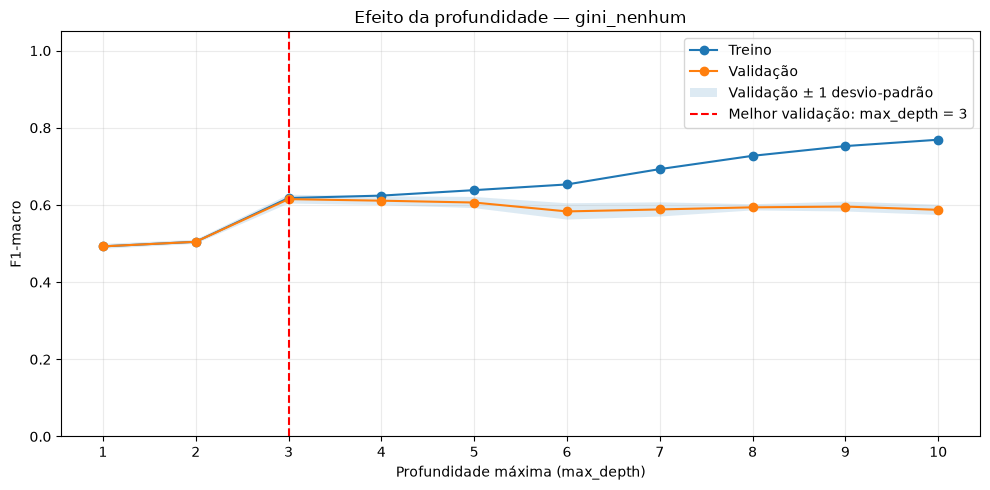

MÉTRICAS DO TESTE — gini_nenhum (ÁRVORE PRÓPRIA)
max_depth escolhido pela CV: 3
F1-macro médio da CV: 0.6151 ± 0.0114
Acurácia: 0.7142
F1-macro: 0.6369
Acurácia balanceada: 0.6317
Concordância com scikit-learn: 100.00%
Tempo mediano de treino: 59.36 ms
Tempo mediano para prever 1000 estudantes: 0.50 ms
Número de atributos após pré-processamento: 85

Métricas por classe:


,Classe,VP,FP,FN,Precisão,Revocação,F1
0,Dropout,278,79,141,0.778711,0.663484,0.716495
1,Enrolled,79,122,146,0.393035,0.351111,0.370892
2,Graduate,545,160,74,0.773050,0.880452,0.823263



CONFIGURAÇÃO: gini_pca


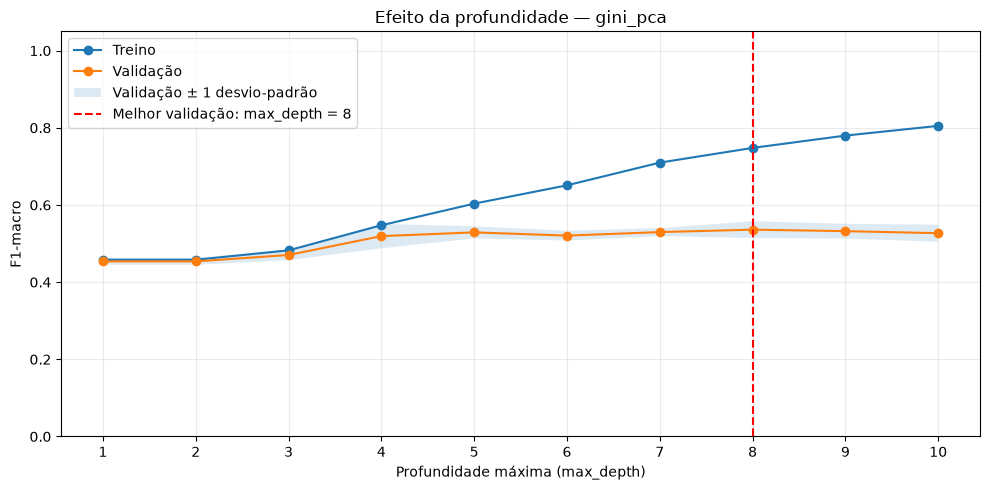

MÉTRICAS DO TESTE — gini_pca (ÁRVORE PRÓPRIA)
max_depth escolhido pela CV: 8
F1-macro médio da CV: 0.5360 ± 0.0219
Acurácia: 0.6334
F1-macro: 0.5530
Acurácia balanceada: 0.5516
Concordância com scikit-learn: 98.34%
Tempo mediano de treino: 481.93 ms
Tempo mediano para prever 1000 estudantes: 0.82 ms
Número de atributos após pré-processamento: 58

Métricas por classe:


,Classe,VP,FP,FN,Precisão,Revocação,F1
0,Dropout,272,130,147,0.676617,0.649165,0.662607
1,Enrolled,54,121,171,0.308571,0.240000,0.270000
2,Graduate,474,212,145,0.690962,0.765751,0.726437



CONFIGURAÇÃO: entropia_nenhum


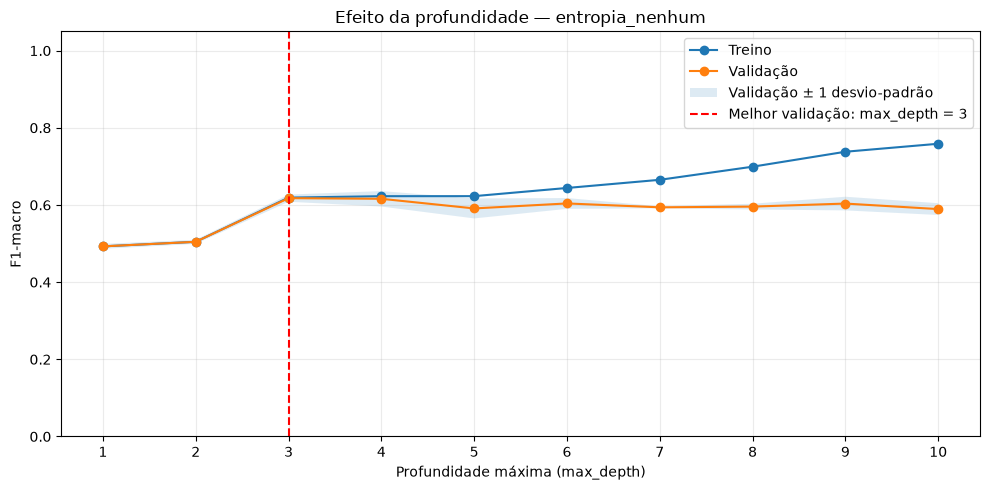

MÉTRICAS DO TESTE — entropia_nenhum (ÁRVORE PRÓPRIA)
max_depth escolhido pela CV: 3
F1-macro médio da CV: 0.6176 ± 0.0093
Acurácia: 0.7142
F1-macro: 0.6369
Acurácia balanceada: 0.6317
Concordância com scikit-learn: 100.00%
Tempo mediano de treino: 64.63 ms
Tempo mediano para prever 1000 estudantes: 0.50 ms
Número de atributos após pré-processamento: 85

Métricas por classe:


,Classe,VP,FP,FN,Precisão,Revocação,F1
0,Dropout,278,79,141,0.778711,0.663484,0.716495
1,Enrolled,79,122,146,0.393035,0.351111,0.370892
2,Graduate,545,160,74,0.773050,0.880452,0.823263



CONFIGURAÇÃO: entropia_pca


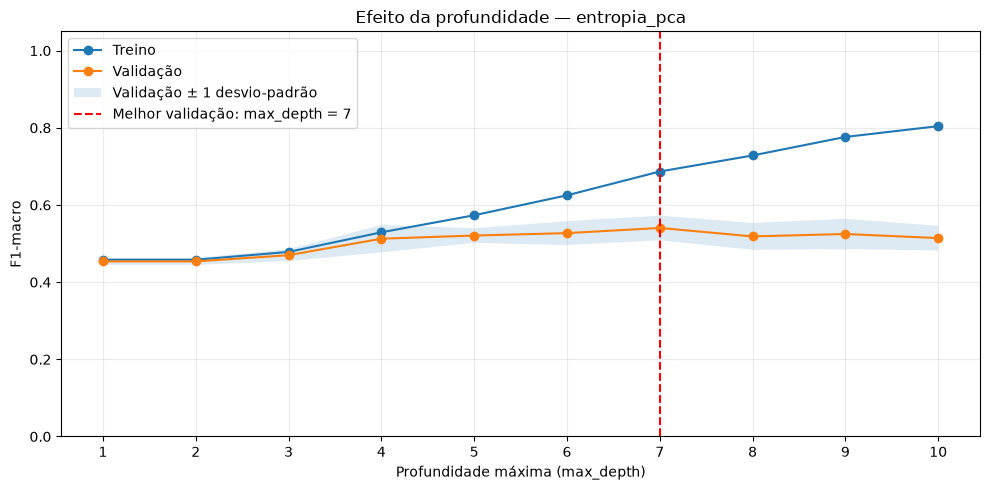

MÉTRICAS DO TESTE — entropia_pca (ÁRVORE PRÓPRIA)
max_depth escolhido pela CV: 7
F1-macro médio da CV: 0.5404 ± 0.0320
Acurácia: 0.6342
F1-macro: 0.5383
Acurácia balanceada: 0.5339
Concordância com scikit-learn: 99.84%
Tempo mediano de treino: 501.31 ms
Tempo mediano para prever 1000 estudantes: 0.75 ms
Número de atributos após pré-processamento: 58

Métricas por classe:


,Classe,VP,FP,FN,Precisão,Revocação,F1
0,Dropout,223,77,196,0.743333,0.532220,0.620306
1,Enrolled,48,114,177,0.296296,0.213333,0.248062
2,Graduate,530,271,89,0.661673,0.856220,0.746479



RESUMO CONSOLIDADO DE TODOS OS CENÁRIOS (ordenado por F1-Macro):


In [ ]:
import time
import numpy as np
import pandas as pd
from IPython.display import display

resultados_consolidados = []

for cenario in cenarios:
    nome = cenario["nome"]
    crit = cenario["criterio"]
    modo = cenario["modo"]
    
    print(f"\n{'='*70}\nCONFIGURAÇÃO: {nome}\n{'='*70}")
    
    df_cv = valida_cruzada(crit, modo)
    melhor_idx = df_cv["F1_validacao_medio"].idxmax()
    melhor_prof = df_cv.loc[melhor_idx, "max_depth"]
    f1_cv = df_cv.loc[melhor_idx, "F1_validacao_medio"]
    f1_cv_std = df_cv.loc[melhor_idx, "F1_validacao_desvio"]
    
    grafico_profundidade(df_cv, nome, melhor_prof)
    
    Xtr, Xte = preprocessar(X_treino, X_teste, modo)
    
    tempos_treino = []
    tempos_pred_total = []
    tempos_pred_1000 = []
    
    arv_sk = criar_arvore(crit, melhor_prof, implementacao="sklearn")
    arv_sk.fit(Xtr, y_treino)
    y_pred_sk = arv_sk.predict(Xte)
    
    for _ in range(5):
        arv_temp = criar_arvore(crit, melhor_prof, implementacao=IMPLEMENTACAO_CV)
        
        t0 = time.perf_counter()
        arv_temp.fit(Xtr, y_treino)
        t1 = time.perf_counter()
        tempos_treino.append((t1 - t0) * 1000)
        
        t0 = time.perf_counter()
        yp = arv_temp.predict(Xte)
        t1 = time.perf_counter()
        
        tempo_total_ms = (t1 - t0) * 1000
        tempos_pred_total.append(tempo_total_ms)
        tempos_pred_1000.append((tempo_total_ms / len(Xte)) * 1000)
        
    tempo_treino_mediano = np.median(tempos_treino)
    tempo_pred_total_mediano = np.median(tempos_pred_total)
    tempo_pred_1000_mediano = np.median(tempos_pred_1000)
    
    arv = criar_arvore(crit, melhor_prof, implementacao=IMPLEMENTACAO_CV)
    arv.fit(Xtr, y_treino)
    y_pred = arv.predict(Xte)
    
    concordancia = np.mean(y_pred == y_pred_sk) * 100
    n_atributos = Xte.shape[1]
    
    M = matriz_confusao(y_teste, y_pred, n_classes=3)
    metricas = relatorio_metricas(M)
    
    print(f"MÉTRICAS DO TESTE — {nome} (ÁRVORE PRÓPRIA)")
    print(f"max_depth escolhido pela CV: {melhor_prof}")
    print(f"F1-macro médio da CV: {f1_cv:.4f} ± {f1_cv_std:.4f}")
    print(f"Acurácia: {metricas['acuracia']:.4f}")
    print(f"F1-macro: {metricas['f1_macro']:.4f}")
    print(f"Acurácia balanceada: {metricas['acuracia_balanceada']:.4f}")
    print(f"Concordância com scikit-learn: {concordancia:.2f}%")
    print(f"Tempo mediano de treino: {tempo_treino_mediano:.2f} ms")
    print(f"Tempo mediano para prever 1000 estudantes: {tempo_pred_1000_mediano:.2f} ms")
    print(f"Número de atributos após pré-processamento: {n_atributos}\n")
    
    print("Métricas por classe:")
    display(tabela_por_classe(metricas))
    
    resultados_consolidados.append({
        "Cenário": nome,
        "Melhor max_depth": melhor_prof,
        "Acurácia": round(metricas['acuracia'], 4),
        "F1-macro": round(metricas['f1_macro'], 4),
        "Treino (ms)": round(tempo_treino_mediano, 2),
        "Predição (ms)": round(tempo_pred_total_mediano, 2),
        "Pred 1000 (ms)": round(tempo_pred_1000_mediano, 2)
    })

print("\nRESUMO CONSOLIDADO DE TODOS OS CENÁRIOS (ordenado por F1-Macro):")
df_resumo = pd.DataFrame(resultados_consolidados)

In [10]:
df_resumo

,Cenário,Melhor max_depth,Acurácia,F1-macro,Treino (ms),Predição (ms),Pred 1000 (ms)
0,gini_nenhum,3,0.7142,0.6369,59.36,0.63,0.50
1,gini_pca,8,0.6334,0.5530,481.93,1.03,0.82
2,entropia_nenhum,3,0.7142,0.6369,64.63,0.63,0.50
3,entropia_pca,7,0.6342,0.5383,501.31,0.95,0.75
